# Project: Young Adult Migration Patterns with Regression  
### Soren Patel

**AI Usage:** Generative AI was utilized as an auxiliary technical assistant throughout this project. Specifically, AI assistance was used to troubleshoot SSL verification errors encountered during Nominatim geocoding and to assist with the structural pivot to the US Census County Gazetteer files for location coordinates. Additionally, AI was used to code and implement extra diagnostic checks (Parts a–f), configure SimpleImputer from scikit-learn for handling missing data, and design the feature ablation methodology to evaluate feature group impacts on model performance. Lastly, it was used to aid the creation of various types of plots and graphs. All code, data processing, and analytical conclusions were verified independently. This was also written by AI.

## Data Loading/Setup/Configuration

Import necessary libraries and give a value to seed random for reproducible results. Also includes flags EXCLUDE_SAME_CZ which when true, will indicate dropping rows for people who did not move. LOG_TARGET flag when true predicts a log(1+n) instead of n, so the range is compressed and right-skewed migration counts do not pull the regression line as heavily. Note we use 1+n inside the log since log(0) is undefined.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 2028
DATA_PATH = "od_pooled.csv"
EXCLUDE_SAME_CZ = True
LOG_TARGET = True

Load the data from od_pooled.csv (main dataset). Each row is one origin and destination pair, with the amount of people who made that move. Print first 5 rows for visualization.

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.columns.tolist())
df.head()

(549081, 12)
['o_cz', 'o_cz_name', 'o_state_name', 'd_cz', 'd_cz_name', 'd_state_name', 'n', 'n_tot_o', 'n_tot_d', 'pool', 'pr_d_o', 'pr_o_d']


,o_cz,o_cz_name,o_state_name,d_cz,d_cz_name,d_state_name,n,n_tot_o,n_tot_d,pool,pr_d_o,pr_o_d
0,6502,Cleveland,Tennessee,100,Johnson City,Tennessee,127.0,22148,56915,pooled,0.005734,0.002231
1,34108,Kodiak,Alaska,100,Johnson City,Tennessee,0.0,1702,56915,pooled,0.000000,0.000000
2,10302,Dothan,Alabama,100,Johnson City,Tennessee,16.0,26182,56915,pooled,0.000611,0.000281
3,5201,New Albany,Mississippi,100,Johnson City,Tennessee,1.0,6530,56915,pooled,0.000153,0.000018
4,29201,Hiawatha,Kansas,100,Johnson City,Tennessee,0.0,2794,56915,pooled,0.000000,0.000000


## Data Exploration  
Answering the following questions will better help us analyze the data since we can better characterize the dataset.  
  
How skewed is n?  
How many rows are 0/NaN?  
Does the file contain same-CZ rows?  
Does every origin-destination pair exist, or only ones with movers?

count    5.490810e+05
mean     5.722583e+01
std      3.263886e+03
min     -2.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      3.000000e+00
max      1.400000e+06
Name: n, dtype: float64

Rows with n < 0: 2388
Rows with n == 0: 284503
Rows with o_cz == d_cz: 741

Unique origins: 741, unique destinations: 741
Rows: 549081 vs all possible pairs: 549081


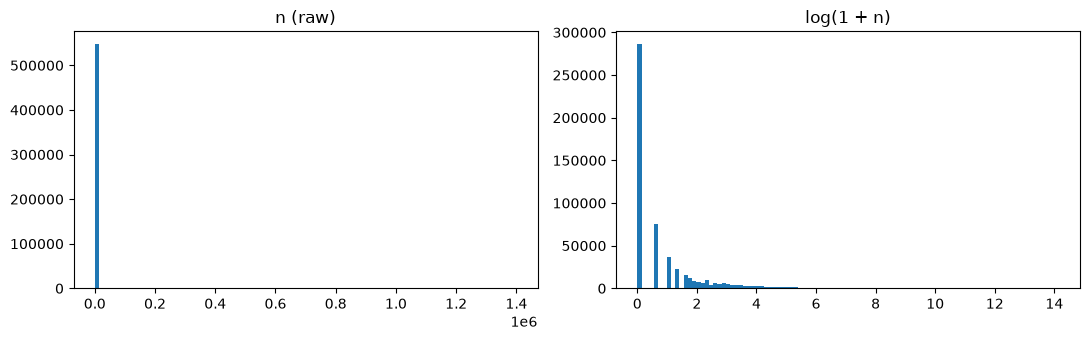

In [3]:
print(df["n"].describe())
print("\nRows with n < 0:", (df["n"] < 0).sum())
print("Rows with n == 0:", (df["n"] == 0).sum())
print("Rows with o_cz == d_cz:", (df["o_cz"] == df["d_cz"]).sum())

n_o, n_d = df["o_cz"].nunique(), df["d_cz"].nunique()
print(f"\nUnique origins: {n_o}, unique destinations: {n_d}")
print(f"Rows: {len(df)} vs all possible pairs: {n_o * n_d}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df["n"].clip(lower=0), bins=100); ax[0].set_title("n (raw)")
ax[1].hist(np.log1p(df["n"].clip(lower=0)), bins=100); ax[1].set_title("log(1 + n)")
plt.tight_layout(); plt.show()

## Clean Data and Define Target for Model

Decisions made:  
1. The negative n values are set to 0 since they most likely come from privacy noise.
2. When EXCLUDE_SAME_CZ flag is true, the same-cz rows are dropped since not moving would skew the line.
3. Target is log(1+n) if LOG_TARGET flag is true, since the counts are heavily right-skewed.

In [4]:
data = df.copy()

if EXCLUDE_SAME_CZ:
    data = data[data["o_cz"] != data["d_cz"]]

n_neg = (data["n"] < 0).sum()
data["n_clean"] = data["n"].clip(lower=0)
print(f"Clipped {n_neg} negative counts to 0")

data["y"] = np.log1p(data["n_clean"]) if LOG_TARGET else data["n_clean"]
data = data.reset_index(drop=True)
print("Rows after cleaning:", len(data))

Clipped 2388 negative counts to 0
Rows after cleaning: 548340


## Split into Train/Test/Validation Data

Split into 80% train, 10% test, 10% validation sets.  
Note: the code may seem unintuitive, but it works by first removing 0.10 as the test set. Then taking 1/9th of that remaining 90% to be the validation set. Rest is the training set.

In [5]:
train_val, test = train_test_split(data, test_size=0.10, random_state=RANDOM_STATE)
train, val = train_test_split(train_val, test_size=1/9, random_state=RANDOM_STATE)

print(f"train: {len(train)}, val: {len(val)}, test: {len(test)}")

train: 438672, val: 54834, test: 54834


## Feature Building Skeleton Function  
This is a skeleton function for building features. Adding features just means editing this function and rerunning.  
First version includes log population of origin-destination.

In [6]:
def build_features(d):
    X = pd.DataFrame(index=d.index)
    X["log_pop_o"] = np.log(d["n_tot_o"].clip(lower=1))
    X["log_pop_d"] = np.log(d["n_tot_d"].clip(lower=1))
    return X

X_train, y_train = build_features(train), train["y"]
X_val,   y_val   = build_features(val),   val["y"]
X_train.describe()

,log_pop_o,log_pop_d
count,438672.000000,438672.000000
mean,9.370405,9.232209
std,1.629880,1.744058
min,4.795791,4.804021
25%,8.402904,8.176392
50%,9.383705,9.253304
75%,10.429221,10.397543
max,14.378155,14.353931


## Regression Function  
This function  
1. Fits a StandardScaler (z-score normalization) to the training data.
2. Tries many Ridge regularization strengths on a log scale.
3. Compares RMSE to the validation set.
4. Returns the model with the lowest validation RMSE.

In [7]:
def fit_best_ridge(X_train, y_train, X_val, y_val, alphas=np.logspace(-4, 4, 33)):
    scaler = StandardScaler().fit(X_train)
    Xt, Xv = scaler.transform(X_train), scaler.transform(X_val)

    best, rows = None, []
    for a in alphas:
        m = Ridge(alpha=a).fit(Xt, y_train)
        rmse = np.sqrt(mean_squared_error(y_val, m.predict(Xv)))
        rows.append((a, rmse))
        if best is None or rmse < best["val_rmse"]:
            best = {"alpha": a, "model": m, "scaler": scaler, "val_rmse": rmse, "val_r2": r2_score(y_val, m.predict(Xv))}
    best["curve"] = pd.DataFrame(rows, columns=["alpha", "val_rmse"])
    best["features"] = list(X_train.columns)
    return best

## Base Model and Experiment Logging   
This first runs the skeleton model, and starts a log of all experiments with features. Each time the set of features changes, it adds a row to the log to show what helped/what didn't. 

In [8]:
experiment_log = []

def run_experiment(name):
    Xtr, Xva = build_features(train), build_features(val)
    res = fit_best_ridge(Xtr, train["y"], Xva, val["y"])
    experiment_log.append({"experiment": name, "n_features": Xtr.shape[1], "best_alpha": res["alpha"], "val_rmse": res["val_rmse"], "val_r2": res["val_r2"]})
    return res

res = run_experiment("baseline: log pop o, log pop d")
pd.DataFrame(experiment_log)

,experiment,n_features,best_alpha,val_rmse,val_r2
0,"baseline: log pop o, log pop d",2,3162.27766,0.978745,0.454545


Show the regularization curve: validation error as a function of alpha, the regularization strength. The best alpha is at the lowest point of the curve. The minimum here is meaningful since error drops and rises before and after.

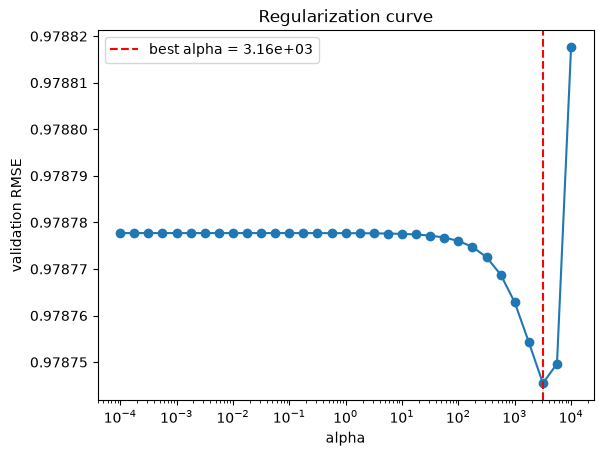

In [9]:
plt.semilogx(res["curve"]["alpha"], res["curve"]["val_rmse"], marker="o")
plt.axvline(res["alpha"], color="red", linestyle="--", label=f"best alpha = {res['alpha']:.3g}")
plt.xlabel("alpha"); plt.ylabel("validation RMSE"); plt.legend(); plt.title("Regularization curve")
plt.show()

## Inspect/Visualize Downloaded Files  
Print first few values of files to be used going forward.

In [10]:
import xlrd

xw = pd.read_csv("commuting-zones-2020.csv")
print("CZ file:", xw.columns.tolist()); display(xw.head(3))

pop_raw = pd.read_csv("co-est2020.csv", encoding="latin-1")
print("\nPopulation:", pop_raw.columns.tolist()[:12]); display(pop_raw.head(3).iloc[:, :8])

display(pd.read_excel("est20all.xls", header=None, nrows=6).iloc[:, :10])

xl = pd.ExcelFile("2020county_health_rankings.xlsx")
print("\nHealth sheets:", xl.sheet_names)
for s in xl.sheet_names[:4]:
    display(pd.read_excel(xl, s, header=None, nrows=3).iloc[:, :8])

CZ file: ['FIPStxt', 'CountyName', 'StateName', 'CZ2020', 'CZName', 'CZContainment', 'CZAvgContainment']


,FIPStxt,CountyName,StateName,CZ2020,CZName,CZContainment,CZAvgContainment
0,1001,Autauga County,Alabama,1,"Montgomery, AL",91.34,89.95
1,1003,Baldwin County,Alabama,2,"Mobile, AL",92.97,84.86
2,1005,Barbour County,Alabama,3,"Dothan, AL",80.04,84.96



Population: ['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'COUNTY', 'STNAME', 'CTYNAME', 'CENSUS2010POP', 'ESTIMATESBASE2010', 'POPESTIMATE2010', 'POPESTIMATE2011', 'POPESTIMATE2012']


,SUMLEV,REGION,DIVISION,STATE,COUNTY,STNAME,CTYNAME,CENSUS2010POP
0,40,3,6,1,0,Alabama,Alabama,4779736
1,50,3,6,1,1,Alabama,Autauga County,54571
2,50,3,6,1,3,Alabama,Baldwin County,182265


,0,1,2,3,4,5,6,7,8,9
0,Table with column headers in rows 3 and 4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020 Poverty and Median Household Income Estim...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Geographic Information,NaN,NaN,NaN,All Ages,NaN,NaN,NaN,NaN,NaN
3,State FIPS Code,County FIPS Code,Postal Code,Name,"Poverty Estimate, All Ages",90% CI Lower Bound,90% CI Upper Bound,"Poverty Percent, All Ages",90% CI Lower Bound,90% CI Upper Bound
4,00,000,US,United States,38371394,38309115,38433673,11.9,11.9,11.9
5,01,000,AL,Alabama,714568,695249,733887,14.9,14.5,15.3



Health sheets: ['Introduction', 'Outcomes & Factors Rankings', 'Outcomes & Factors SubRankings', 'Ranked Measure Data', 'Ranked Measure Sources & Years', 'Additional Measure Data', 'Addtl Measure Sources & Years']


,0
0,NaN
1,A collaboration between the Robert Wood Johnso...
2,NaN


,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,Health Outcomes,NaN,Health Factors,NaN
1,FIPS,State,County,# of Ranked Counties,Rank,Quartile,Rank,Quartile
2,01000,Alabama,NaN,67,NaN,NaN,NaN,NaN


,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,NaN,Length of Life,NaN,Quality of Life,NaN
1,FIPS,State,County,# of Ranked Counties,Rank,Quartile,Rank,Quartile
2,01000,Alabama,NaN,67,NaN,NaN,NaN,NaN


,0,1,2,3,4,5,6,7
0,NaN,NaN,NaN,Premature death,NaN,NaN,NaN,NaN
1,FIPS,State,County,Deaths,Years of Potential Life Lost Rate,95% CI - Low,95% CI - High,Quartile
2,01000,Alabama,NaN,81791,9942.794666,9840.535949,10045.053384,NaN


## CZ Coordinates from County Centroids  
Each county's center (using the Census Gazetteer since Nominatim was rate limiting in the request speed and took very long time to run) is mapped to a CZ and averaged. This is the crosswalk file, it maps the county level to CZ level. Includes a check for Washington Co TN, and Bradley Co TN to map to od_pooled IDs.

In [11]:
XWALK_FILE = "cz00eqvv1.xls"
XWALK_FIPS_COL = "FIPS"
XWALK_CZ_COL = "Commuting Zone ID, 1990"

xw90 = pd.read_excel(XWALK_FILE) if XWALK_FILE.endswith((".xls", ".xlsx")) else pd.read_csv(XWALK_FILE)
xwalk = xw90.rename(columns={XWALK_FIPS_COL: "fips", XWALK_CZ_COL: "cz"})[["fips", "cz"]].dropna()
xwalk["fips"], xwalk["cz"] = xwalk["fips"].astype(int), xwalk["cz"].astype(int)
fips_to_cz = dict(zip(xwalk["fips"], xwalk["cz"]))

w, b = fips_to_cz.get(47179), fips_to_cz.get(47011)
print(f"Washington Co TN -> {w} (od_pooled: Johnson City = 100) | Bradley Co TN -> {b} (od_pooled: Cleveland = 6502)")
assert (w, b) == (100, 6502), "CZ IDs don't match od_pooled; see note below"

gaz = pd.read_csv("2020_Gaz_counties_national.txt", sep="\t", dtype={"GEOID": str})
gaz.columns = gaz.columns.str.strip()
gaz = gaz.rename(columns={"GEOID": "fips", "INTPTLAT": "lat", "INTPTLONG": "lon"})
gaz["fips"] = gaz["fips"].astype(int)
gaz["cz"] = gaz["fips"].map(fips_to_cz)

cz_feats = (gaz.dropna(subset=["cz"]).assign(cz=lambda x: x["cz"].astype(int))
               .groupby("cz")[["lat", "lon"]].mean())
cz_feats.index.name = "cz"

cz_table = pd.concat([
    df[["o_cz", "o_cz_name", "o_state_name"]].set_axis(["cz", "name", "state"], axis=1),
    df[["d_cz", "d_cz_name", "d_state_name"]].set_axis(["cz", "name", "state"], axis=1),
]).drop_duplicates("cz").reset_index(drop=True)

missing = cz_table[~cz_table["cz"].isin(cz_feats.index)]
print(f"CZs in od_pooled: {len(cz_table)} | with coordinates: {len(cz_table) - len(missing)}")
display(missing)

Washington Co TN -> 100 (od_pooled: Johnson City = 100) | Bradley Co TN -> 6502 (od_pooled: Cleveland = 6502)
CZs in od_pooled: 741 | with coordinates: 740


,cz,name,state
33,34103,Valdez,Alaska


This is the one missing zone, so we patch it with this.

In [12]:
print(gaz[gaz["fips"].isin([2063, 2066, 2261])][["fips", "lat", "lon"]])

succ = gaz[gaz["fips"].isin([2063, 2066])]
if len(succ) == 2:
    cz_feats.loc[34103, ["lat", "lon"]] = [succ["lat"].mean(), succ["lon"].mean()]
else:
    cz_feats.loc[34103, ["lat", "lon"]] = [61.13, -146.35]

print(cz_feats.loc[[34103]])
print("CZs still missing:", (~cz_table["cz"].isin(cz_feats.index)).sum())   # should print 0
cz_feats.to_csv("cz_feats.csv")

    fips        lat         lon
72  2063  60.488474 -146.203092
73  2066  62.034479 -143.922167
             lat        lon
cz                         
34103  61.261477 -145.06263
CZs still missing: 0


## Population  
Gives pop per CZ and the weights for the averaged datasets. Also defines two helper functions. county_to_cz takes a county level table up to CZ level with a population mean for rates, and sum for counts. add_cz_cols joins the result to cz_feats.

In [13]:
def county_to_cz(county_df, value_cols=(), weight_col=None, sum_cols=()):
    c = county_df.copy()
    c["cz"] = c["fips"].map(fips_to_cz)
    c = c.dropna(subset=["cz"])
    c["cz"] = c["cz"].astype(int)
    out = pd.DataFrame(index=sorted(c["cz"].unique()))
    out.index.name = "cz"
    for col in value_cols:
        sub = c.dropna(subset=[col] + ([weight_col] if weight_col else []))
        if weight_col:
            out[col] = ((sub[col] * sub[weight_col]).groupby(sub["cz"]).sum() / sub[weight_col].groupby(sub["cz"]).sum())
        else:
            out[col] = sub.groupby("cz")[col].mean()
    for col in sum_cols:
        out[col] = c.groupby("cz")[col].sum()
    return out

def add_cz_cols(new):
    global cz_feats
    cz_feats = cz_feats.drop(columns=[c for c in new.columns if c in cz_feats.columns]).join(new)
    cz_feats.to_csv("cz_feats.csv")
    cov = cz_feats.reindex(cz_table["cz"]).isna().sum()
    print("CZs missing each column (out of", len(cz_table), "):")
    print(cov[new.columns].to_string())

pop_raw = pd.read_csv("co-est2020.csv", encoding="latin-1")
pop_raw = pop_raw[pop_raw["SUMLEV"] == 50]
pop_county = pd.DataFrame({"fips": pop_raw["STATE"] * 1000 + pop_raw["COUNTY"],
                           "pop": pop_raw["POPESTIMATE2010"]})
add_cz_cols(county_to_cz(pop_county, sum_cols=["pop"]))

CZs missing each column (out of 741 ):
pop    1


## Poverty and Median Income  
State-level rows have county code 000 -> dropped. Poverty rate and median household income are population weighted to CZ.

In [14]:
pov_raw = pd.read_excel("est20all.xls", header=3)
print([c for c in pov_raw.columns if "Median" in str(c) or "Poverty Percent" in str(c)])

pov_raw["sf"] = pd.to_numeric(pov_raw["State FIPS Code"], errors="coerce")
pov_raw["cf"] = pd.to_numeric(pov_raw["County FIPS Code"], errors="coerce")
pov_raw = pov_raw[pov_raw["cf"] > 0]
pov_raw["fips"] = (pov_raw["sf"] * 1000 + pov_raw["cf"]).astype(int)
pov_raw["poverty_pct"] = pd.to_numeric(pov_raw["Poverty Percent, All Ages"], errors="coerce")
pov_raw["median_income"] = pd.to_numeric(pov_raw["Median Household Income"], errors="coerce")

add_cz_cols(county_to_cz(pov_raw[["fips", "poverty_pct", "median_income"]].merge(pop_county, on="fips"), ["poverty_pct", "median_income"], weight_col="pop"))

['Poverty Percent, All Ages', 'Poverty Percent, Age 0-17', 'Poverty Percent, Age 5-17 in Families', 'Median Household Income', 'Poverty Percent, Age 0-4']
CZs missing each column (out of 741 ):
poverty_pct      1
median_income    1


## County Health Rankings  

In [15]:
hr = pd.read_excel("2020county_health_rankings.xlsx", sheet_name="Ranked Measure Data", header=1)
hr = hr[hr["County"].notna()]

def find_col(frame, text):
    hits = [c for c in frame.columns if text.lower() in str(c).lower()]
    print(f"'{text}' ->", hits)
    return hits[0]

poor_col = find_col(hr, "Fair or Poor")
obese_col = find_col(hr, "Obesity")

health_county = pd.DataFrame({"fips": pd.to_numeric(hr["FIPS"], errors="coerce"), "poor_health_pct": pd.to_numeric(hr[poor_col], errors="coerce"), "obesity_pct": pd.to_numeric(hr[obese_col], errors="coerce")}).dropna(subset=["fips"])
health_county["fips"] = health_county["fips"].astype(int)

add_cz_cols(county_to_cz(health_county.merge(pop_county, on="fips"), ["poor_health_pct", "obesity_pct"], weight_col="pop"))

'Fair or Poor' -> ['% Fair or Poor Health']
'Obesity' -> ['% Adults with Obesity']
CZs missing each column (out of 741 ):
poor_health_pct    1
obesity_pct        1


## Feature Groups Functions  
Each feature group is a function below, these return a Pandas DF of columns, so experiments choose groups by name. Includes a sanity check at bottom to ensure distances are human-interpretable and in proper units of km.

In [16]:
def lookup(d, col, side):
    return cz_feats[col].reindex(d[f"{side}_cz"]).to_numpy()

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def pair_km(d):
    return haversine_km(lookup(d, "lat", "o"), lookup(d, "lon", "o"), lookup(d, "lat", "d"), lookup(d, "lon", "d"))

def f_pop(d):
    return pd.DataFrame({"log_pop_o": np.log(d["n_tot_o"].clip(lower=1)), "log_pop_d": np.log(d["n_tot_d"].clip(lower=1))}, index=d.index)

def f_pop_census(d):
    return pd.DataFrame({"log_pop_o": np.log(lookup(d, "pop", "o")), "log_pop_d": np.log(lookup(d, "pop", "d"))}, index=d.index)

def f_distance_lin(d):
    return pd.DataFrame({"log_dist": np.log1p(pair_km(d))}, index=d.index)

def f_distance(d):
    ld = np.log1p(pair_km(d))
    return pd.DataFrame({"log_dist": ld, "log_dist_sq": ld ** 2}, index=d.index)

def f_same_state(d):
    return pd.DataFrame({"same_state": (d["o_state_name"] == d["d_state_name"]).astype(int)}, index=d.index)

def f_same_cz(d):
    return pd.DataFrame({"same_cz": (d["o_cz"] == d["d_cz"]).astype(int)}, index=d.index)

def f_dest_econ(d):
    return pd.DataFrame({"pov_d": lookup(d, "poverty_pct", "d"), "log_inc_d": np.log(lookup(d, "median_income", "d"))}, index=d.index)

def f_origin_econ(d):
    return pd.DataFrame({"pov_o": lookup(d, "poverty_pct", "o"), "log_inc_o": np.log(lookup(d, "median_income", "o"))}, index=d.index)

def f_econ_gap(d):
    return pd.DataFrame({"pov_gap": lookup(d, "poverty_pct", "d") - lookup(d, "poverty_pct", "o"), "log_inc_gap": np.log(lookup(d, "median_income", "d")) - np.log(lookup(d, "median_income", "o"))}, index=d.index)

def f_health(d):
    out = {}
    for c in ["poor_health_pct", "obesity_pct"]:
        o, dd = lookup(d, c, "o"), lookup(d, c, "d")
        out.update({f"{c}_o": o, f"{c}_d": dd, f"{c}_gap": dd - o})
    return pd.DataFrame(out, index=d.index)

def f_ideology(d): 
    o, dd = lookup(d, "ideology", "o"), lookup(d, "ideology", "d")
    return pd.DataFrame({"ideo_o": o, "ideo_d": dd, "ideo_gap": np.abs(dd - o)}, index=d.index)

def f_interact(d): 
    return pd.DataFrame({"dist_x_pop_d": np.log1p(pair_km(d)) * np.log(lookup(d, "pop", "d"))}, index=d.index)

FEATURE_FUNCS = {"pop": f_pop, "pop_census": f_pop_census, "distance_lin": f_distance_lin,
                 "distance": f_distance, "same_state": f_same_state, "same_cz": f_same_cz,
                 "dest_econ": f_dest_econ, "origin_econ": f_origin_econ, "econ_gap": f_econ_gap,
                 "health": f_health, "ideology": f_ideology, "interact": f_interact}

def build_features(d, groups):
    return pd.concat([FEATURE_FUNCS[g](d) for g in groups], axis=1)

print(pd.Series(pair_km(train)).describe().round(1))
ex = df[(df["o_cz"] == 6502) & (df["d_cz"] == 100)].iloc[:1]
print("Cleveland TN -> Johnson City TN (km):", pair_km(ex).round(1))

count    438672.0
mean       1627.2
std        1150.7
min          23.5
25%         862.5
50%        1384.9
75%        2045.3
max        8483.4
dtype: float64
Cleveland TN -> Johnson City TN (km): [241.5]


## Experiment Running  
Builds features, fills missing values with training set medians, fits the scaler on the training data, and tunes alpha based on the validation data. Results are logged.

In [17]:
from sklearn.impute import SimpleImputer

experiment_log = []

def make_xy(groups, tr=None, va=None):
    tr = train if tr is None else tr
    va = val if va is None else va
    Xtr_raw, Xva_raw = build_features(tr, groups), build_features(va, groups)
    n_missing = int(Xva_raw.isna().any(axis=1).sum())
    imp = SimpleImputer(strategy="median").fit(Xtr_raw)
    Xtr = pd.DataFrame(imp.transform(Xtr_raw), columns=Xtr_raw.columns, index=Xtr_raw.index)
    Xva = pd.DataFrame(imp.transform(Xva_raw), columns=Xva_raw.columns, index=Xva_raw.index)
    return Xtr, Xva, imp, n_missing

def prep(res, d):
    raw = build_features(d, res["groups"])
    X = pd.DataFrame(res["imputer"].transform(raw), columns=raw.columns, index=raw.index)
    return res["scaler"].transform(X)

def predict(res, d):
    return res["model"].predict(prep(res, d))

def count_metrics(res, d):
    p = predict(res, d)
    if LOG_TARGET:
        p = np.expm1(p)
    p = np.clip(p, 0, None)
    err = d["n_clean"].to_numpy() - p
    return {"rmse_people": float(np.sqrt(np.mean(err ** 2))), "mae_people": float(np.mean(np.abs(err)))}

def run_experiment(name, groups, tr=None, va=None, log=True):
    tr = train if tr is None else tr
    va = val if va is None else va
    Xtr, Xva, imp, n_missing = make_xy(groups, tr, va)
    res = fit_best_ridge(Xtr, tr["y"], Xva, va["y"])
    res["imputer"], res["groups"] = imp, list(groups)
    if log:
        cm = count_metrics(res, va)
        experiment_log.append({"experiment": name, "groups": "+".join(groups),
                               "n_features": Xtr.shape[1], "best_alpha": res["alpha"],
                               "val_rmse": res["val_rmse"], "val_r2": res["val_r2"],
                               "val_rmse_people": cm["rmse_people"], "val_mae_people": cm["mae_people"],
                               "val_rows_with_missing": n_missing})
    return res

## Experiment Hypotheses  
This cell clears the experiment log, so running it is starting fresh. However there are two baselines: one is naive and predicts the training mean for every pair. The other is the skeleton, log populations only.  

My hypotheses:  
| Feature group | What I expect | Why |
|---|---|---|
| distance | Biggest gain | People mostly move near where they grew up |
| same_state | Small gain on top of distance | In-state ties, tuition, familiarity |
| dest_econ | Moderate gain | Young adults move toward jobs |
| econ_gap | Moderate gain | A linear model cannot form differences itself |
| health | Little or no gain | Probably correlated with income and poverty |
| interact | Small gain | Large destinations draw from farther away |
| pop_census | Little change vs the n_tot | Removes a mild target leak |

In [18]:
experiment_log.clear()

naive_log = np.full(len(val), train["y"].mean())
naive_people = np.full(len(val), train["n_clean"].mean())
experiment_log.append({
    "experiment": "naive: training mean", "groups": "-", "n_features": 0, "best_alpha": np.nan,
    "val_rmse": float(np.sqrt(mean_squared_error(val["y"], naive_log))), "val_r2": 0.0,
    "val_rmse_people": float(np.sqrt(np.mean((val["n_clean"] - naive_people) ** 2))),
    "val_mae_people": float(np.mean(np.abs(val["n_clean"] - naive_people))),
    "val_rows_with_missing": 0})

res = run_experiment("skeleton: pop", ["pop"])
pd.DataFrame(experiment_log).round(4)

,experiment,groups,n_features,best_alpha,val_rmse,val_r2,val_rmse_people,val_mae_people,val_rows_with_missing
0,naive: training mean,-,0,NaN,1.3252,0.0000,155.8892,28.7948,0
1,skeleton: pop,pop,2,3162.2777,0.9787,0.4545,154.9561,15.8030,0


## Forward Experiments  
1. add each candidate group to the skeleton so individual contributions/changes can be seen
2. stack groups in order, only keep one if it lowers the validation RMSE by the min. gain. 

In [19]:
candidate_groups = ["distance", "same_state", "dest_econ", "econ_gap", "health", "interact"]

for g in candidate_groups:
    run_experiment(f"pop + {g}", ["pop", g])

MIN_GAIN = 1e-3 
current = ["pop"]
best_rmse = experiment_log[1]["val_rmse"] 
for g in candidate_groups:
    trial = run_experiment(f"stack: {'+'.join(current)} + {g}", current + [g])
    if trial["val_rmse"] < best_rmse - MIN_GAIN:
        current.append(g); best_rmse = trial["val_rmse"]
        print(f"kept {g}: val RMSE {best_rmse:.4f}")
    else:
        print(f"dropped {g}: val RMSE {trial['val_rmse']:.4f} (no meaningful gain)")

print("Selected groups:", current)
pd.DataFrame(experiment_log).round(4)

kept distance: val RMSE 0.8319
kept same_state: val RMSE 0.8134
kept dest_econ: val RMSE 0.7972
kept econ_gap: val RMSE 0.7898
kept health: val RMSE 0.7732
kept interact: val RMSE 0.7636
Selected groups: ['pop', 'distance', 'same_state', 'dest_econ', 'econ_gap', 'health', 'interact']


,experiment,groups,n_features,best_alpha,val_rmse,val_r2,val_rmse_people,val_mae_people,val_rows_with_missing
0,naive: training mean,-,0,NaN,1.3252,0.0000,155.8892,28.7948,0
1,skeleton: pop,pop,2,3162.2777,0.9787,0.4545,154.9561,15.8030,0
2,pop + distance,pop+distance,4,31.6228,0.8319,0.6059,147.1176,14.5329,0
3,pop + same_state,pop+same_state,3,3162.2777,0.8845,0.5545,149.7164,15.1213,0
4,pop + dest_econ,pop+dest_econ,4,3162.2777,0.9697,0.4646,154.7138,15.7356,79
5,pop + econ_gap,pop+econ_gap,4,3162.2777,0.9778,0.4556,154.9524,15.7949,156
6,pop + health,pop+health,8,3162.2777,0.9637,0.4712,154.5708,15.6923,156
7,pop + interact,pop+interact,3,1000.0000,0.8940,0.5449,153.1833,15.4298,79
8,stack: pop + distance,pop+distance,4,31.6228,0.8319,0.6059,147.1176,14.5329,0
9,stack: pop+distance + same_state,pop+distance+same_state,5,56.2341,0.8134,0.6232,143.9832,14.1266,0


## Swap in Census Population  
Final model uses census population. This swaps it in and logs RMSE movement.

In [20]:
swapped = [("pop_census" if g == "pop" else g) for g in current]
run_experiment("swap pop -> pop_census", swapped)
current = swapped
pd.DataFrame(experiment_log).round(4).tail(3)

,experiment,groups,n_features,best_alpha,val_rmse,val_r2,val_rmse_people,val_mae_people,val_rows_with_missing
12,stack: pop+distance+same_state+dest_econ+econ_...,pop+distance+same_state+dest_econ+econ_gap+health,15,56.2341,0.7732,0.6596,140.4639,13.6999,156
13,stack: pop+distance+same_state+dest_econ+econ_...,pop+distance+same_state+dest_econ+econ_gap+hea...,16,31.6228,0.7636,0.6680,134.4637,13.1618,156
14,swap pop -> pop_census,pop_census+distance+same_state+dest_econ+econ_...,16,56.2341,0.7761,0.6570,134.2654,13.2466,156


## Removing Tests  
From the best-stacked model, remove one group at a time, and check the raising of RMSE. If RMSE raises a lot, that indicates an important group. On the other hand, little RMSE change indicates a redundant/useless group.

In [21]:
best_groups = list(current)
full = run_experiment("FULL: " + "+".join(best_groups), best_groups)
abl = []
for g in best_groups:
    r = run_experiment(f"full minus {g}", [x for x in best_groups if x != g])
    abl.append({"removed": g, "val_rmse": r["val_rmse"], "increase": r["val_rmse"] - full["val_rmse"]})
pd.DataFrame(abl).sort_values("increase", ascending=False).round(4)

,removed,val_rmse,increase
0,pop_census,0.9187,0.1426
1,distance,0.8029,0.0268
2,same_state,0.7931,0.0170
5,health,0.7924,0.0163
3,dest_econ,0.7890,0.0129
6,interact,0.7812,0.0051
4,econ_gap,0.7800,0.0039


## Additional Checks  
I want to see if the model and choices thus far are reliable. To do so we can perform extra checks which use make_xy, run_experiment, and predict from above. These do not touch the test set.  
- a: cross-validation on the training set
- b: Lasso as an alternative regularizer
- c: gravity-model check
- d: same-CZ rows
- e: nonlinear reference model
- f: multicollinearity

a: cross validation using a scaler refit inside each fold giving a steadier check on alpha.

In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, KFold

def cv_rmse(groups, k=5):
    X, y = build_features(train, groups), train["y"]
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge())
    gs = GridSearchCV(pipe, {"ridge__alpha": np.logspace(-4, 4, 17)},
                      cv=KFold(k, shuffle=True, random_state=RANDOM_STATE),
                      scoring="neg_root_mean_squared_error")
    gs.fit(X, y)
    return -gs.best_score_, gs.best_params_["ridge__alpha"]

rows = []
for name, g in [("skeleton", ["pop"]), ("best stacked", best_groups)]:
    score, a = cv_rmse(g)
    rows.append({"model": name, "cv_rmse": score, "cv_best_alpha": a})
pd.DataFrame(rows).round(4)

,model,cv_rmse,cv_best_alpha
0,skeleton,0.9815,10.0
1,best stacked,0.7744,1.0


b: Lasso regression for regularization vs. ridge. 

In [23]:
from sklearn.linear_model import Lasso

def fit_best_lasso(groups, alphas=np.logspace(-5, 1, 25)):
    Xtr, Xva, imp, _ = make_xy(groups)
    sc = StandardScaler().fit(Xtr)
    Xt, Xv = sc.transform(Xtr), sc.transform(Xva)
    best = None
    for a in alphas:
        m = Lasso(alpha=a, max_iter=10000).fit(Xt, train["y"])
        rmse = np.sqrt(mean_squared_error(val["y"], m.predict(Xv)))
        if best is None or rmse < best["val_rmse"]:
            best = {"alpha": a, "val_rmse": rmse, "coef": pd.Series(m.coef_, index=Xtr.columns)}
    return best

lasso = fit_best_lasso(best_groups)
print(f"Lasso best alpha {lasso['alpha']:.3g}, val RMSE {lasso['val_rmse']:.4f} (Ridge: {full['val_rmse']:.4f})")
print("Features set to zero:", list(lasso["coef"][lasso["coef"] == 0].index))
lasso["coef"].sort_values(key=abs, ascending=False)

Lasso best alpha 0.0001, val RMSE 0.7761 (Ridge: 0.7761)
Features set to zero: ['poor_health_pct_d', 'obesity_pct_gap']


log_dist_sq            2.761512
log_dist              -2.561787
log_pop_d              1.445639
dist_x_pop_d          -1.046581
log_pop_o              0.538896
log_inc_d              0.406526
pov_d                  0.326545
log_inc_gap           -0.204441
same_state             0.187270
pov_gap               -0.176208
obesity_pct_d         -0.146191
poor_health_pct_o     -0.142037
poor_health_pct_gap   -0.086418
obesity_pct_o         -0.068889
poor_health_pct_d     -0.000000
obesity_pct_gap        0.000000
dtype: float64

c: Gravity model check

In [24]:
grav = run_experiment("gravity: pop_census + log distance", ["pop_census", "distance_lin"])
raw_coefs = pd.Series(grav["model"].coef_ / grav["scaler"].scale_, index=grav["features"])
print("Coefficients in raw log units (elasticities):")
print(raw_coefs.round(3))

Coefficients in raw log units (elasticities):
log_pop_o    0.347
log_pop_d    0.391
log_dist    -0.534
dtype: float64


d: Keep same CZ rows, and compare model accordingly.

In [25]:
all_rows = df.reset_index(drop=True).copy()
all_rows["n_clean"] = all_rows["n"].clip(lower=0)
all_rows["y"] = np.log1p(all_rows["n_clean"]) if LOG_TARGET else all_rows["n_clean"]
tv2, te2 = train_test_split(all_rows, test_size=0.10, random_state=RANDOM_STATE)
tr2, va2 = train_test_split(tv2, test_size=1/9, random_state=RANDOM_STATE)

base = [g for g in best_groups if g != "same_cz"]
r_without = run_experiment("with same-CZ rows, no indicator", base, tr=tr2, va=va2, log=False)
r_with = run_experiment("with same-CZ rows + indicator", base + ["same_cz"], tr=tr2, va=va2, log=False)
print(f"No indicator:   val RMSE {r_without['val_rmse']:.4f}")
print(f"With indicator: val RMSE {r_with['val_rmse']:.4f}")

No indicator:   val RMSE 0.7876
With indicator: val RMSE 0.7721


e: Nonlinear reference: gradient boosting on the same features. The gap between this and the linear model shows what structure the linear model is missing.

In [26]:
from sklearn.ensemble import HistGradientBoostingRegressor

Xtr_g, Xva_g, _, _ = make_xy(best_groups)
gb = HistGradientBoostingRegressor(random_state=RANDOM_STATE).fit(Xtr_g, train["y"])
gb_rmse = np.sqrt(mean_squared_error(val["y"], gb.predict(Xva_g)))
print(f"Gradient boosting val RMSE: {gb_rmse:.4f}  vs  Ridge: {full['val_rmse']:.4f}")

Gradient boosting val RMSE: 0.4910  vs  Ridge: 0.7761


f: Multicollinearity: measuring the correlation and variance inflation factor between poverty, income, and health measures since they are likely correlated.

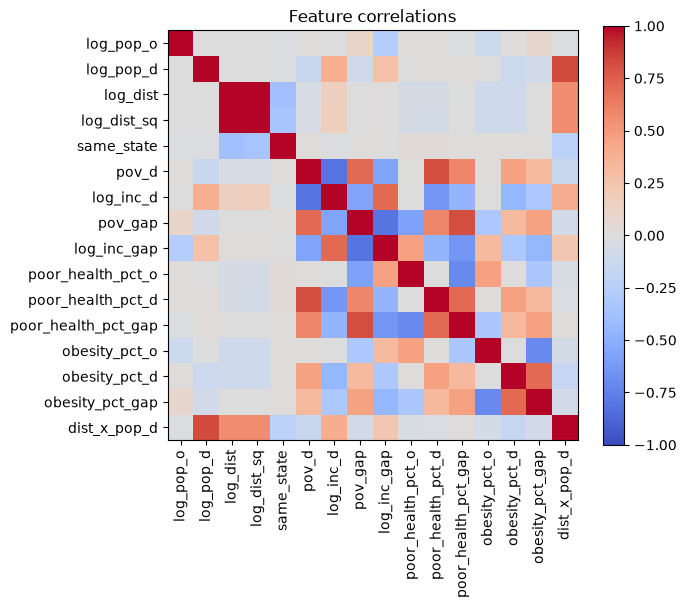

obesity_pct_gap        921.75
poor_health_pct_gap    858.83
obesity_pct_d          462.38
obesity_pct_o          460.50
poor_health_pct_d      432.24
poor_health_pct_o      427.72
log_dist               235.25
log_dist_sq            180.57
dist_x_pop_d           132.11
log_pop_d               92.43
pov_d                   10.97
pov_gap                 10.60
log_inc_d                8.91
log_inc_gap              8.20
log_pop_o                1.44
same_state               1.41
dtype: float64

In [27]:
from sklearn.linear_model import LinearRegression

corr = Xtr_g.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
plt.colorbar(im); plt.title("Feature correlations"); plt.tight_layout(); plt.show()

def vif(X):
    out = {}
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out[c] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

vif(Xtr_g).round(2)

## Final Model and Test Evaluation  
This locks in the feature set and best alpha from the validation tests. It is evaluated only once based on those.

In [28]:
final_groups = best_groups
res = run_experiment("FINAL", final_groups)
print("Final groups:", final_groups, "| alpha:", res["alpha"], "| val RMSE:", round(res["val_rmse"], 4))

RUN_FINAL = True
if RUN_FINAL:
    pred = predict(res, test)
    print("Test RMSE (target units):", np.sqrt(mean_squared_error(test["y"], pred)))
    print("Test R^2:", r2_score(test["y"], pred))
    print("Test (people):", count_metrics(res, test))

Final groups: ['pop_census', 'distance', 'same_state', 'dest_econ', 'econ_gap', 'health', 'interact'] | alpha: 56.23413251903491 | val RMSE: 0.7761
Test RMSE (target units): 0.7742321528555445
Test R^2: 0.6608733921751155
Test (people): {'rmse_people': 169.03388818546, 'mae_people': 13.747413571215276}


## Analysis

Features are standardizes, so we can compare coefficient sizes, as the sign and magnitude give direction and weight/importance respectively. Refit on resampled training data at the chosen alpha.

,coef,ci_low,ci_high,significant
log_dist_sq,2.6762,2.6390,2.7106,True
log_dist,-2.4709,-2.5096,-2.4280,True
log_pop_d,1.4526,1.4177,1.4853,True
dist_x_pop_d,-1.0558,-1.0954,-1.0141,True
log_pop_o,0.5381,0.5352,0.5406,True
log_inc_d,0.4122,0.4043,0.4186,True
pov_d,0.3315,0.3239,0.3382,True
log_inc_gap,-0.2090,-0.2147,-0.2027,True
obesity_pct_d,-0.1946,-0.2398,-0.1498,True
poor_health_pct_o,-0.1941,-0.2336,-0.1378,True


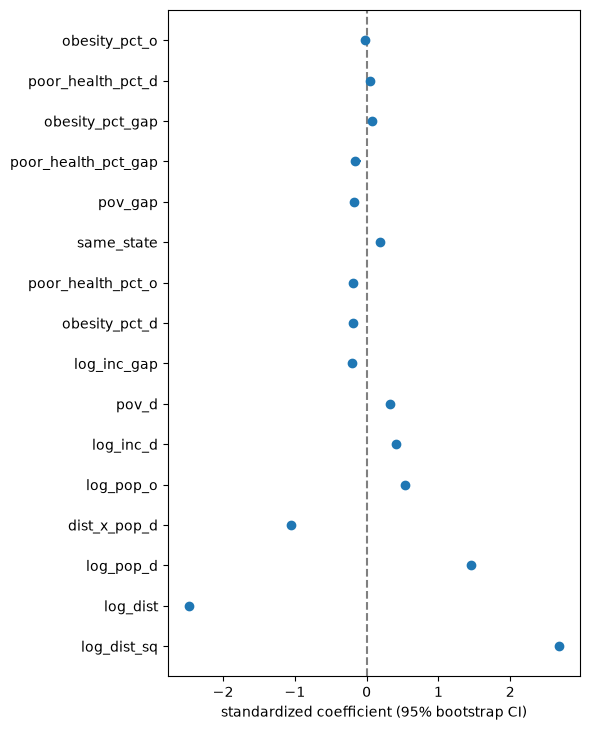

In [29]:
coefs = pd.Series(res["model"].coef_, index=res["features"])
Xs, y_arr = prep(res, train), train["y"].to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
boot = np.empty((200, Xs.shape[1]))
for b in range(200):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot[b] = Ridge(alpha=res["alpha"]).fit(Xs[idx], y_arr[idx]).coef_

ci = pd.DataFrame({"coef": coefs, "ci_low": np.percentile(boot, 2.5, axis=0), "ci_high": np.percentile(boot, 97.5, axis=0)}).sort_values("coef", key=abs, ascending=False)
ci["significant"] = (ci["ci_low"] > 0) | (ci["ci_high"] < 0)
display(ci.round(4))

fig, ax = plt.subplots(figsize=(6, 0.4 * len(ci) + 1))
ax.errorbar(ci["coef"], range(len(ci)), xerr=[ci["coef"] - ci["ci_low"], ci["ci_high"] - ci["coef"]], fmt="o")
ax.set_yticks(range(len(ci))); ax.set_yticklabels(ci.index); ax.axvline(0, color="gray", linestyle="--")
ax.set_xlabel("standardized coefficient (95% bootstrap CI)"); plt.tight_layout(); plt.show()

Two contrasting pairs of origin-destination with different characteristics are tested here. The two pairs we choose are Casper, WY to Seattle, WA (sparse/red to dense/blue) and Boston, MA to Dallas, TX (dense/blue to dense/red). Both are long distances, but the first pair is small flow expected and the second is large flow expected.

In [31]:
test[(test["n"] >= 20) & (test["n"] <= 300)][["o_cz_name", "o_state_name", "d_cz_name", "d_state_name", "n"]]. \
    sort_values("n", ascending=False).head(40)

,o_cz_name,o_state_name,d_cz_name,d_state_name,n
122764,Jackson,Mississippi,Washington DC,DC,300.0
395648,El Paso,Texas,Lubbock,Texas,300.0
529793,Flagstaff,Arizona,San Diego,California,300.0
76456,Providence,Rhode Island,Cape Coral,Florida,300.0
409294,Texarkana,Texas,Austin,Texas,299.0
409288,Nashville,Tennessee,Austin,Texas,298.0
548222,Toms River,New Jersey,Seattle,Washington,296.0
197759,Richmond,Virginia,Newark,New Jersey,295.0
526610,El Paso,Texas,San Francisco,California,295.0
207425,Miami,Florida,Providence,Rhode Island,294.0


In [32]:
PAIRS = {
    "A: Casper WY -> Seattle WA":  ("Casper", "Wyoming", "Seattle", "Washington"),
    "B: Boston MA -> Dallas TX":   ("Boston", "Massachusetts", "Dallas", "Texas"),
}

def find_pair(o_name, o_state, d_name, d_state):
    m = data[data["o_cz_name"].str.contains(o_name, case=False, regex=False) & (data["o_state_name"] == o_state) & data["d_cz_name"].str.contains(d_name, case=False, regex=False) & (data["d_state_name"] == d_state)]
    return m

for label, spec in PAIRS.items():
    m = find_pair(*spec)
    print(label, "->", len(m), "match(es)")
    if len(m) != 1:
        display(m[["o_cz", "o_cz_name", "o_state_name", "d_cz", "d_cz_name", "d_state_name", "n"]])

A: Casper WY -> Seattle WA -> 1 match(es)
B: Boston MA -> Dallas TX -> 1 match(es)


In [33]:
test_abs_resid = (test["y"] - predict(res, test)).abs()

out = {}
for label, spec in PAIRS.items():
    m = find_pair(*spec)
    if m.empty:
        print("not found:", label); continue
    i = m.index[0]
    row = data.loc[[i]]
    split = "train" if i in train.index else "val" if i in val.index else "test"
    p = predict(res, row)[0]
    p_n = max(np.expm1(p), 0) if LOG_TARGET else max(p, 0)
    actual = row["n_clean"].iloc[0]
    resid = row["y"].iloc[0] - p
    out[label] = {
        "split (test = out-of-sample)": split,
        "actual movers": actual,
        "predicted movers": round(p_n, 1),
        "error (people)": round(p_n - actual, 1),
        "residual (target units)": round(resid, 3),
        "abs error percentile in test set": f"{(test_abs_resid < abs(resid)).mean():.0%}",
        "distance (km)": round(float(pair_km(row)[0]), 0),
        "origin pop": f"{lookup(row, 'pop', 'o')[0]:,.0f}",
        "dest pop": f"{lookup(row, 'pop', 'd')[0]:,.0f}",
        "origin poverty %": round(float(lookup(row, "poverty_pct", "o")[0]), 1),
        "dest poverty %": round(float(lookup(row, "poverty_pct", "d")[0]), 1),
        "origin median income": f"{lookup(row, 'median_income', 'o')[0]:,.0f}",
        "dest median income": f"{lookup(row, 'median_income', 'd')[0]:,.0f}",
        "same state": row["o_state_name"].iloc[0] == row["d_state_name"].iloc[0],
    }

pd.DataFrame(out)

,A: Casper WY -> Seattle WA,B: Boston MA -> Dallas TX
split (test = out-of-sample),train,train
actual movers,95.0,682.0
predicted movers,13.7,45.1
error (people),-81.3,-636.9
residual (target units),1.874,2.696
abs error percentile in test set,98%,100%
distance (km),1363.0,2476.0
origin pop,"89,300","5,164,258"
dest pop,"4,285,937","4,198,387"
origin poverty %,9.2,8.9


**Notes from the table above:**
Both pairs are under-predicted and both landed in the train set. Pair B is worse, having an error of -637 people vs. -81. Looking at it scaled, the model is off by about 15x on Boston -> Dallas and 6.5x on Casper -> Seattle. This indicates that the model is underfitting. 

## Where the Model Fails  
Test if errors depend on distance using the validation set so it can change the model without touching test set.

In [34]:
diag = val[["o_cz_name", "o_state_name", "d_cz_name", "d_state_name", "n_clean", "y"]].copy()
diag["resid"] = diag["y"] - predict(res, val)
diag["km"] = pair_km(val)
diag["dist_bin"] = pd.qcut(diag["km"], 5, duplicates="drop")
display(diag.groupby("dist_bin", observed=True)["resid"].agg(["mean", "std", "count"]).round(3))

cols = ["o_cz_name", "o_state_name", "d_cz_name", "d_state_name", "n_clean", "resid"]
print("Most under-predicted:"); display(diag.nlargest(10, "resid")[cols])
print("Most over-predicted:");  display(diag.nsmallest(10, "resid")[cols])

,mean,std,count
dist_bin,,,
"(44.157000000000004, 746.271]",-0.057,0.862,10967
"(746.271, 1166.481]",-0.014,0.756,10967
"(1166.481, 1614.972]",0.023,0.726,10966
"(1614.972, 2243.967]",0.029,0.733,10967
"(2243.967, 8327.35]",-0.010,0.793,10967


Most under-predicted:


,o_cz_name,o_state_name,d_cz_name,d_state_name,n_clean,resid
75446,New York,New York,Miami,Florida,6624.0,4.659575
547959,Honolulu,Hawaii,Seattle,Washington,2309.0,4.393680
527254,Chicago,Illinois,Las Vegas,Nevada,2434.0,4.369015
527606,Detroit,Michigan,Las Vegas,Nevada,1677.0,4.304835
531656,Newark,New Jersey,Los Angeles,California,5405.0,4.228013
196310,San Francisco,California,New York,New York,5705.0,4.088654
505593,Los Angeles,California,Salt Lake City,Utah,5251.0,4.087649
531487,Honolulu,Hawaii,Los Angeles,California,2492.0,4.028095
196361,Atlanta,Georgia,New York,New York,6078.0,3.980551
8463,New York,New York,Charlotte,North Carolina,3649.0,3.938899


Most over-predicted:


,o_cz_name,o_state_name,d_cz_name,d_state_name,n_clean,resid
545439,Port Angeles,Washington,Friday Harbor,Washington,4.0,-3.384581
13917,Boone,North Carolina,Andrews,North Carolina,0.0,-3.240384
70588,Statesboro,Georgia,Ellijay,Georgia,0.0,-2.994929
70887,Dublin,Georgia,Ellijay,Georgia,0.0,-2.892830
198073,Middlesborough,Tennessee,Newark,New Jersey,0.0,-2.862524
1610,Tullahoma,Tennessee,Middlesborough,Tennessee,0.0,-2.803198
107486,Milledgeville,Georgia,Eufaula,Georgia,0.0,-2.752799
197784,Welch,West Virginia,Newark,New Jersey,0.0,-2.749299
407919,Midland,Texas,La Grange,Texas,0.0,-2.727500
105191,Auburn,Alabama,Bainbridge,Georgia,0.0,-2.699417


## Parental Income Quintiles  
Test if distance and destination economy matter differently for the poorest and richest quintiles (Q1 and Q5 respectively).

In [35]:
inc = pd.read_csv("od_inc.csv")

def fit_pool(pool_df, groups, name):
    d = pool_df.copy()
    if EXCLUDE_SAME_CZ:
        d = d[d["o_cz"] != d["d_cz"]]
    d["n_clean"] = d["n"].clip(lower=0)
    d["y"] = np.log1p(d["n_clean"]) if LOG_TARGET else d["n_clean"]
    d = d.reset_index(drop=True)
    tv, _ = train_test_split(d, test_size=0.10, random_state=RANDOM_STATE)
    tr, va = train_test_split(tv, test_size=1/9, random_state=RANDOM_STATE)
    return run_experiment(name, groups, tr=tr, va=va, log=False)

inc_groups = [("pop_census" if g == "pop" else g) for g in final_groups]
fits = {q: fit_pool(inc[inc["pool"] == q], inc_groups, f"income {q}") for q in ["Q1", "Q5"]}

comp = pd.DataFrame({q: pd.Series(r["model"].coef_, index=r["features"]) for q, r in fits.items()})
comp["Q5 - Q1"] = comp["Q5"] - comp["Q1"]
print({q: round(r["val_rmse"], 4) for q, r in fits.items()})
comp.round(3)

{'Q1': np.float64(0.582), 'Q5': np.float64(0.615)}


,Q1,Q5,Q5 - Q1
log_pop_o,0.269,0.269,0.000
log_pop_d,1.180,1.205,0.025
log_dist,-1.459,-0.827,0.631
log_dist_sq,1.838,1.251,-0.587
same_state,0.132,0.112,-0.020
pov_d,0.209,0.301,0.092
log_inc_d,0.196,0.374,0.178
pov_gap,-0.155,-0.179,-0.023
log_inc_gap,-0.122,-0.245,-0.123
poor_health_pct_o,-0.137,-0.176,-0.039


## Final Model Regularization Curve

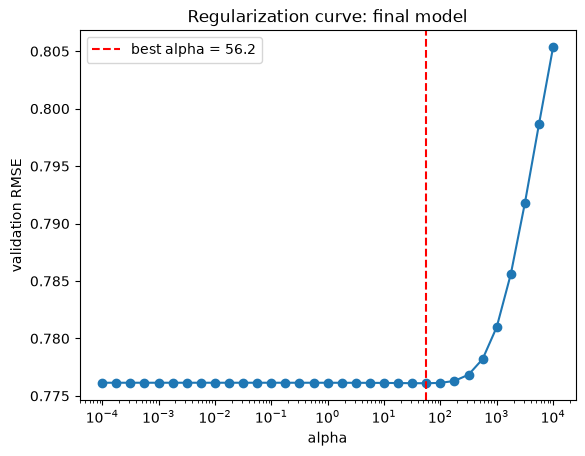

log_pop_o              0.319
log_pop_d              0.861
log_dist              -3.418
log_dist_sq            0.265
same_state             1.148
pov_d                  0.073
log_inc_d              2.123
pov_gap               -0.028
log_inc_gap           -0.761
poor_health_pct_o     -0.045
poor_health_pct_d      0.012
poor_health_pct_gap   -0.026
obesity_pct_o         -0.004
obesity_pct_d         -0.042
obesity_pct_gap        0.011
dist_x_pop_d          -0.071
dtype: float64

In [36]:
   plt.semilogx(res["curve"]["alpha"], res["curve"]["val_rmse"], marker="o")
   plt.axvline(res["alpha"], color="red", linestyle="--", label=f"best alpha = {res['alpha']:.3g}")
   plt.xlabel("alpha"); plt.ylabel("validation RMSE"); plt.legend(); plt.title("Regularization curve: final model")
   plt.show()

   raw_final = pd.Series(res["model"].coef_ / res["scaler"].scale_, index=res["features"])
   raw_final.round(3)

## Closing out Hypotheses  

| Group | I predicted | What happened (validation RMSE) |
|---|---|---|
| distance | biggest gain | Confirmed: 0.979 → 0.832, far larger than any other group |
| same_state | small gain | Confirmed: −0.019 |
| dest_econ / econ_gap | moderate | Smaller than expected (−0.016, −0.007), and nearly useless alone (0.970, 0.978 vs 0.979) until distance is in |
| health | little or none | Wrong: −0.017, as big as dest_econ |
| interact | small | Small in log units (−0.010), but the largest drop in people-scale RMSE (140.5 → 134.5) |
| pop_census | little change | Worse by 0.0125 in log units, flat in people. |

Checking the importance of features puts pop_census first, and the distance looks smaller than it actually is becuause dist_x_pop_d also contains distance.

## Limitations

Some limitations:  
1. The linear model misses a lot of structure, likely due to CZ specific influence or pull
2. 2388 negative counts were clipped (dataset limitation)
3. County medians were averaged up to CZ level, and the Valdez, AK county was missing and manually patched.

## Conclusions and Key Takeaways

1. Distance is the overwhelming driver of migration choices. Incorporating distance caused the largest single drop in validation RMSE (0.979 -> 0.832), which indicates that migration is disproportionally in favor of nearby zones rather than far ones. This makes practical sense due to the lower financial and time costs of a shorter move, as well as people's desire to remain close to family. Within this as well, staying within the same state provided a consistant RMSE drop, having the same reasoning.
2. The secondary drivers of migration are likely economic and health factors. Looking at distance in combination with economic dest/econ gap factors become more meaningful. Interaction effects may also have pull, in combination with distance, since they produced a large reduction in people-scale RMSE (140.5 -> 134.5 people).
3. Evaluating the models which targeted log scale vs. normal scale showed that the log method did not always align with real world counts. This shows that converting to a human-readable and interpretible scale is important.
4. Future extensions of this model given more time to work on it could incorporate additional factors for young adults like college enrollment statistics, job seeking, and housing markets. 